# Runtimes

runtimes_all = [
    
    [time_ssh2, time_ssh4, time_ssh8, time_ssh12],  # position 0
    [time_ssh2, time_ssh4, time_ssh8, time_ssh12],  # position 1
    [time_ssh2, time_ssh4, time_ssh8, time_ssh12]   # position 2
]

In [14]:
import numpy as np
from pathlib import Path

dir_run_info = Path('data/all_run_info')
dir_run_info.mkdir(parents=True, exist_ok=True)

runtimes_CPRiter = np.load(f"{dir_run_info}/runtimes_CPRiter.npy")
runtimes_IDC = np.load(f"{dir_run_info}/runtimes_IDC.npy")

import pandas as pd

history_IROC = pd.read_csv(f"{dir_run_info}/IROC_history.csv")

history_IROC


,Position,SSH_Order,Stage,Shape,Iterations,Stage_Time_s,Total_Time_s,Total_Iterations
0,position3,2,1,"(30, 30, 30)",4,1.910239,49.629080,10
1,position3,2,2,"(50, 50, 50)",4,12.890379,49.629080,10
2,position3,2,3,"(111, 111, 111)",2,34.828398,49.629080,10
3,position3,4,1,"(30, 30, 30)",6,4.878345,61.584139,13
4,position3,4,2,"(50, 50, 50)",5,22.551725,61.584139,13
5,position3,4,3,"(111, 111, 111)",2,34.153825,61.584139,13
6,position3,8,1,"(30, 30, 30)",11,10.166543,97.062451,22
7,position3,8,2,"(50, 50, 50)",9,50.987145,97.062451,22
8,position3,8,3,"(111, 111, 111)",2,35.908417,97.062451,22
9,position3,12,1,"(30, 30, 30)",50,56.684957,335.688118,82


In [15]:
runtime_per_run = history_IROC.drop_duplicates(
    subset=["Position", "SSH_Order"]
)

mean_runtime_IROC = (
    runtime_per_run
    .groupby("SSH_Order")["Total_Time_s"]
    .agg(["mean", "std"])
    .reset_index()
)

mean_runtime_IROC["mean_min"] = mean_runtime_IROC["mean"] / 60
mean_runtime_IROC["std_min"] = mean_runtime_IROC["std"] / 60

mean_runtimes_IDC = np.mean(runtimes_IDC)
std_runtimes_IDC = np.std(runtimes_IDC)

print("IDC", "Mean:", int(mean_runtimes_IDC), "±", int(std_runtimes_IDC))

mean_runtime_IROC

IDC Mean: 401 ± 2


,SSH_Order,mean,std,mean_min,std_min
0,2,43.719121,5.118773,0.728652,0.085313
1,4,53.209975,8.126719,0.886833,0.135445
2,8,89.859735,6.248003,1.497662,0.104133
3,12,317.169036,16.049863,5.286151,0.267498


IDC: 401 ± 2 s


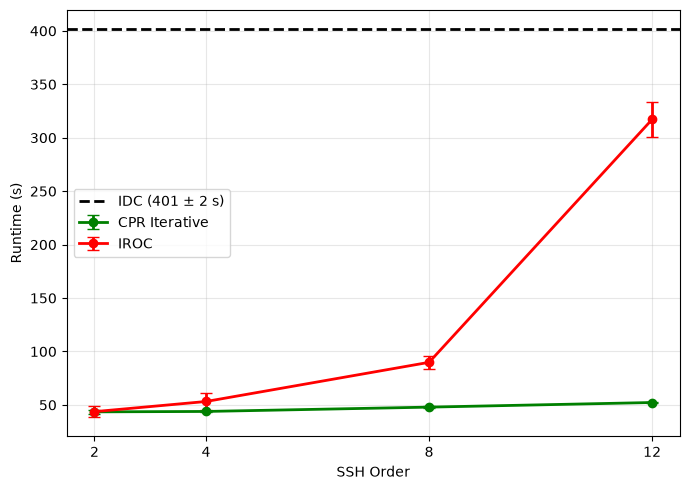

In [16]:
import numpy as np
import matplotlib.pyplot as plt


# ========================================================
# IROC runtime statistics
# ========================================================

runtime_per_run = history_IROC.drop_duplicates(
    subset=["Position", "SSH_Order"]
)

mean_runtime_IROC = (
    runtime_per_run
    .groupby("SSH_Order")["Total_Time_s"]
    .agg(["mean", "std"])
    .reset_index()
    .sort_values("SSH_Order")
)

mean_runtime_IROC["mean_min"] = mean_runtime_IROC["mean"] / 60
mean_runtime_IROC["std_min"] = mean_runtime_IROC["std"] / 60


# ========================================================
# IDC runtime statistics
# ========================================================

mean_runtimes_IDC = np.mean(runtimes_IDC)
std_runtimes_IDC = np.std(runtimes_IDC, ddof=1)

print(
    "IDC:",
    f"{mean_runtimes_IDC:.0f} ± {std_runtimes_IDC:.0f} s"
)


# ========================================================
# Extract IROC values for plotting
# ========================================================

ssh_orders = mean_runtime_IROC["SSH_Order"].to_numpy()

mean_runtimes_IROC = mean_runtime_IROC["mean"].to_numpy()
std_runtimes_IROC = mean_runtime_IROC["std"].to_numpy()


# ========================================================
# CPR runtime statistics
# ========================================================

mean_runtimes_CPR = np.mean(runtimes_CPRiter, axis=0)
std_runtimes_CPR = np.std(runtimes_CPRiter, axis=0, ddof=1)


# ========================================================
# Plot
# ========================================================

fig, ax = plt.subplots(figsize=(7, 5))


# CPR Iterative
ax.errorbar(
    ssh_orders,
    mean_runtimes_CPR,
    yerr=std_runtimes_CPR,
    color="green",
    marker="o",
    markersize=6,
    linewidth=2,
    capsize=4,
    label="CPR Iterative"
)


# IROC
ax.errorbar(
    ssh_orders,
    mean_runtimes_IROC,
    yerr=std_runtimes_IROC,
    color="red",
    marker="o",
    markersize=6,
    linewidth=2,
    capsize=4,
    label="IROC"
)


# IDC
ax.axhline(
    mean_runtimes_IDC,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"IDC ({mean_runtimes_IDC:.0f} ± {std_runtimes_IDC:.0f} s)"
)


# ========================================================
# Formatting
# ========================================================

ax.set_xlabel("SSH Order")
ax.set_ylabel("Runtime (s)")
ax.set_xticks(ssh_orders)

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()